# network

In [2]:
import torch
from torch import nn


class Network(nn.Module):
    """使用指定隐藏层数和激活函数构建全连接网络。"""

    def __init__(
        self,
        input_size: int,
        hidden_size: int,
        output_size: int,
        depth: int,
        act: type[nn.Module] = nn.Tanh,
    ) -> None:
        super().__init__()
        if depth < 1:
            raise ValueError("depth atleast 1")

        layers: list[nn.Module] = []
        for layer_index in range(depth):
            in_features = input_size if layer_index == 0 else hidden_size
            layers.extend([nn.Linear(in_features, hidden_size), act()])

        # 输出层不使用激活函数，允许预测值覆盖正负实数。
        layers.append(nn.Linear(hidden_size, output_size))
        self.layers = nn.Sequential(*layers)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """将形状为 (..., input_size) 的输入映射为 (..., output_size) 的输出。"""
        return self.layers(x)


# train

In [5]:
import math
import torch
import numpy as np
from network import Network

# 定义一个类，用于实现PINN(Physics-informed Neural Networks)
class PINN:
    # 构造函数
    def __init__(self):
        # 选择使用GPU还是CPU
        device = torch.device(
            "cuda") if torch.cuda.is_available() else torch.device("cpu")
        
        # 定义神经网络
        self.model = Network(
            input_size=2,  # 输入层神经元数
            hidden_size=16,  # 隐藏层神经元数
            output_size=1,  # 输出层神经元数
            depth=8,  # 隐藏层数
            act=torch.nn.Tanh  # 输入层和隐藏层的激活函数
        ).to(device)  # 将这个神经网络存储在GPU上（若GPU可用）

        self.h = 0.1  # 设置空间步长
        self.k = 0.1  # 设置时间步长
        x = torch.arange(-1, 1 + self.h, self.h)  # 在[-1,1]区间上均匀取值，记为x
        t = torch.arange(0, 1 + self.k, self.k)  # 在[0,1]区间上均匀取值，记为t

        # 将x和t组合，形成时间空间网格，记录在张量X_inside中
        self.X_inside = torch.stack(torch.meshgrid(x, t, indexing='xy')).reshape(2, -1).T

        # 边界处的时空坐标
        bc1 = torch.stack(torch.meshgrid(x[0], t, indexing='xy')).reshape(2, -1).T  # x=-1边界
        bc2 = torch.stack(torch.meshgrid(x[-1], t, indexing='xy')).reshape(2, -1).T  # x=+1边界
        ic = torch.stack(torch.meshgrid(x, t[0], indexing='xy')).reshape(2, -1).T  # t=0边界
        self.X_boundary = torch.cat([bc1, bc2, ic])  # 将所有边界处的时空坐标点整合为一个张量

        # 边界处的u值
        u_bc1 = torch.zeros(len(bc1))  # x=-1边界处采用第一类边界条件u=0
        u_bc2 = torch.zeros(len(bc2))  # x=+1边界处采用第一类边界条件u=0
        u_ic = -torch.sin(math.pi * ic[:, 0])  # t=0边界处采用第一类边界条件u=-sin(pi*x)
        self.U_boundary = torch.cat([u_bc1, u_bc2, u_ic])  # 将所有边界处的u值整合为一个张量
        self.U_boundary = self.U_boundary.unsqueeze(1)

        # 将数据拷贝到GPU
        self.X_inside = self.X_inside.to(device)
        self.X_boundary = self.X_boundary.to(device)
        self.U_boundary = self.U_boundary.to(device)
        self.X_inside.requires_grad = True  # 设置：需要计算对X的梯度

        # 设置准则函数为MSE，方便后续计算MSE
        self.criterion = torch.nn.MSELoss()

        # 定义迭代序号，记录调用了多少次loss
        self.iter = 1

        # 设置lbfgs优化器
        self.lbfgs = torch.optim.LBFGS(
            self.model.parameters(),
            lr=1.0,
            max_iter=50000,
            max_eval=50000,
            history_size=50,
            tolerance_grad=1e-7,
            tolerance_change=1.0 * np.finfo(float).eps,
            line_search_fn="strong_wolfe",
        )

        # 设置adam优化器
        self.adam = torch.optim.Adam(self.model.parameters())

    # 损失函数
    def loss_func(self):
        # 将导数清零
        self.adam.zero_grad()
        self.lbfgs.zero_grad()

        # 第一部分loss: 边界条件不吻合产生的loss
        U_pred_boundary = self.model(self.X_boundary)  # 使用当前模型计算u在边界处的预测值
        loss_boundary = self.criterion(
            U_pred_boundary, self.U_boundary)  # 计算边界处的MSE

        # 第二部分loss:内点非物理产生的loss
        U_inside = self.model(self.X_inside)  # 使用当前模型计算内点处的预测值

        # 使用自动求导方法得到U对X的导数
        du_dX = torch.autograd.grad(
            inputs=self.X_inside,
            outputs=U_inside,
            grad_outputs=torch.ones_like(U_inside),
            retain_graph=True,
            create_graph=True
        )[0]
        du_dx = du_dX[:, 0]  # 提取对第x的导数
        du_dt = du_dX[:, 1]  # 提取对第t的导数

        # 使用自动求导方法得到U对X的二阶导数
        du_dxx = torch.autograd.grad(
            inputs=self.X_inside,
            outputs=du_dX,
            grad_outputs=torch.ones_like(du_dX),
            retain_graph=True,
            create_graph=True
        )[0][:, 0]
        loss_equation = self.criterion(
            du_dt + U_inside.squeeze() * du_dx, 0.01 / math.pi * du_dxx)  # 计算物理方程的MSE

        # 最终的loss由两项组成
        loss = loss_equation + loss_boundary

        # loss反向传播，用于给优化器提供梯度信息
        loss.backward()

        # 每计算100次loss在控制台上输出消息
        if self.iter % 100 == 0:
            print(self.iter, loss.item())
        self.iter = self.iter + 1
        return loss

    # 训练
    def train(self):
        self.model.train()  # 设置模型为训练模式

        # 首先运行5000步Adam优化器
        print("采用Adam优化器")
        for i in range(5000):
            self.adam.step(self.loss_func)
        # 然后运行lbfgs优化器
        print("采用L-BFGS优化器")
        self.lbfgs.step(self.loss_func)

# 实例化PINN
pinn = PINN()

# 开始训练
pinn.train()

# 将模型保存到文件
torch.save(pinn.model, 'model.pth')


采用Adam优化器
100 0.1670893132686615
200 0.10138802975416183
300 0.052239466458559036
400 0.04832632839679718
500 0.04830893501639366
600 0.04554382711648941
700 0.04526820778846741
800 0.0441044457256794
900 0.043247006833553314
1000 0.04372240602970123
1100 0.041147805750370026
1200 0.04129745066165924
1300 0.04161351919174194
1400 0.04155505448579788
1500 0.03867034986615181
1600 0.03824988007545471
1700 0.039250895380973816
1800 0.04284214228391647
1900 0.04008842259645462
2000 0.03490951284766197
2100 0.03525126352906227
2200 0.03187089413404465
2300 0.03431466594338417
2400 0.031139597296714783
2500 0.03835761547088623
2600 0.028837502002716064
2700 0.029414890334010124
2800 0.03137578070163727
2900 0.027663087472319603
3000 0.034853845834732056
3100 0.02668898180127144
3200 0.02504081092774868
3300 0.03049909695982933
3400 0.02500493824481964
3500 0.02509189210832119
3600 0.027771346271038055
3700 0.02453126385807991
3800 0.025482995435595512
3900 0.02338617853820324
4000 0.02350672

# evaluate

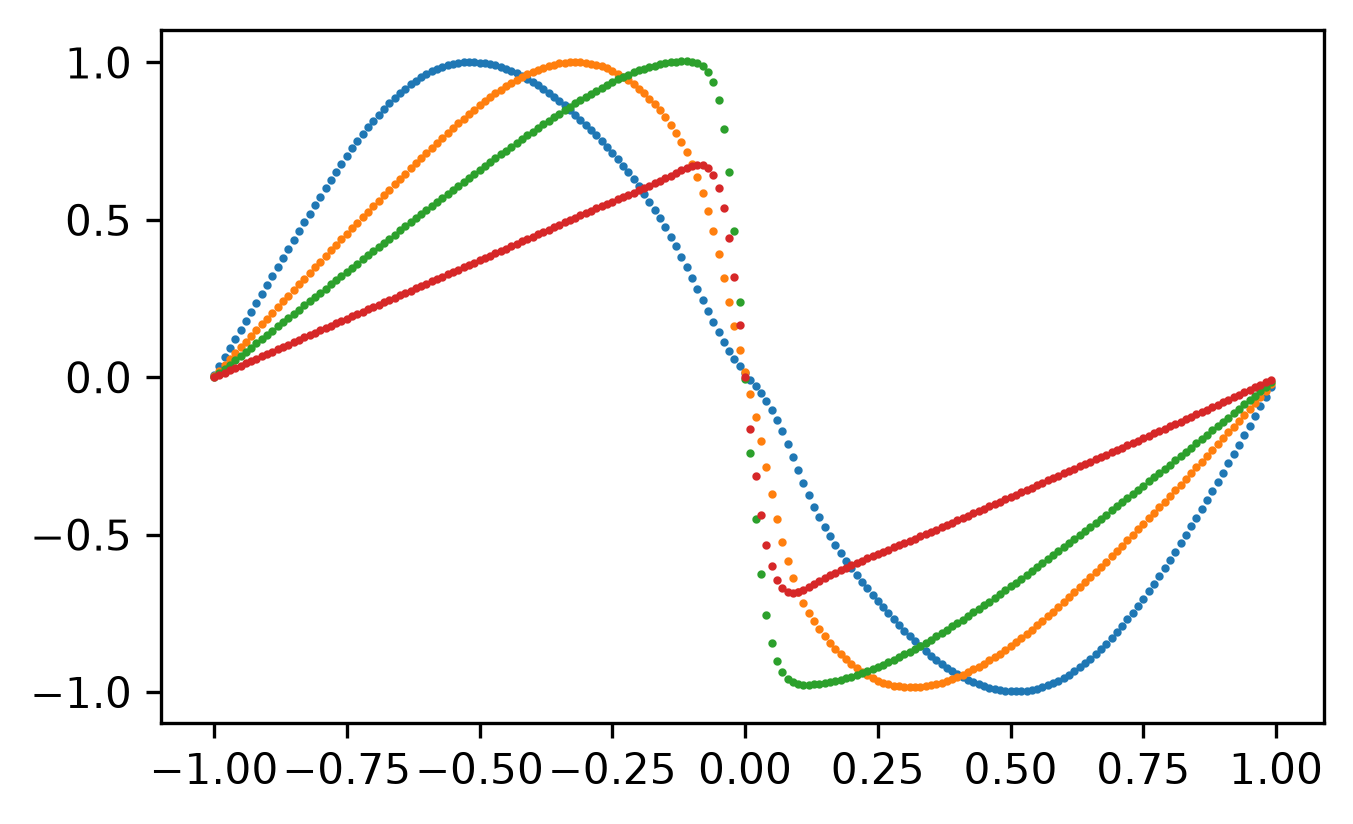

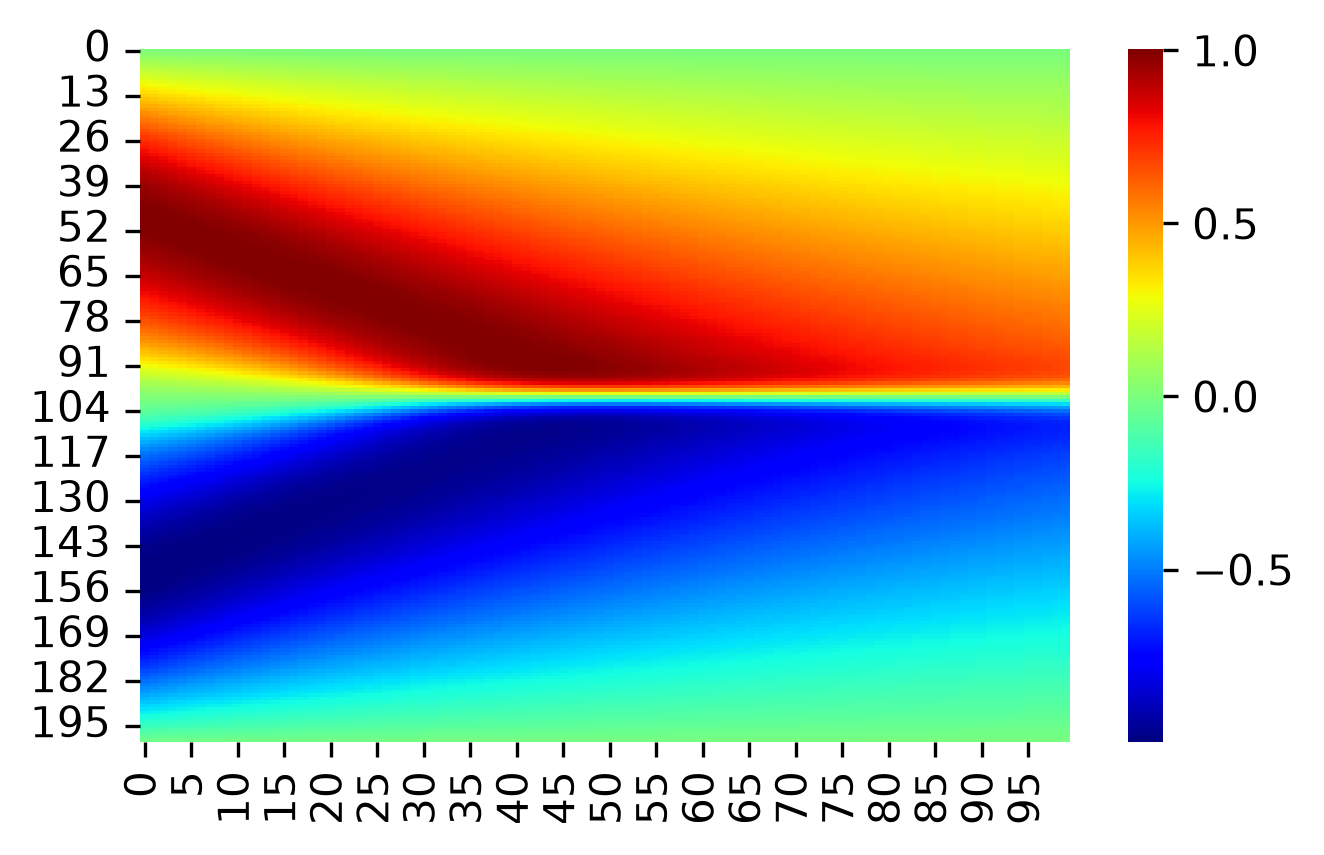

In [6]:
import torch
import seaborn as sns
import matplotlib.pyplot as plt

# 选择GPU或CPU
device = torch.device(
    "cuda") if torch.cuda.is_available() else torch.device("cpu")

# 从文件加载已经训练完成的模型
model_loaded = torch.load('model.pth', map_location=device, weights_only=False)
model_loaded.eval()  # 设置模型为evaluation状态

# 生成时空网格
h = 0.01
k = 0.01
x = torch.arange(-1, 1, h)
t = torch.arange(0, 1, k)
X = torch.stack(torch.meshgrid(x, t)).reshape(2, -1).T
X = X.to(device)

# 计算该时空网格对应的预测值
with torch.no_grad():
    U_pred = model_loaded(X).reshape(len(x), len(t)).cpu().numpy()

# 绘制计算结果
plt.figure(figsize=(5, 3), dpi=300)
xnumpy = x.numpy()
plt.plot(xnumpy, U_pred[:, 0], 'o', markersize=1)
plt.plot(xnumpy, U_pred[:, 20], 'o', markersize=1)
plt.plot(xnumpy, U_pred[:, 40], 'o', markersize=1)
plt.plot(xnumpy, U_pred[:, 99], 'o', markersize=1)
plt.savefig('pinn-line.jpg')
plt.figure(figsize=(5, 3), dpi=300)
sns.heatmap(U_pred, cmap='jet')
plt.savefig('pinn.jpg')
